In [39]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
os.makedirs("../reports/figures", exist_ok=True)

train = pd.read_csv("../data/processed/train.csv")
test = pd.read_csv("../data/processed/test.csv")
y_train = train.pop("is_default")
y_test = test.pop("is_default")
print(train.shape, test.shape)

(586626, 22) (146657, 22)


In [41]:
numeric_applicant = ["loan_amnt", "term_months", "log_income", "dti", "fico_avg",
                     "delinq_2yrs", "open_acc", "pub_rec", "revol_bal", "revol_util",
                     "total_acc", "emp_length_yrs", "emp_length_missing",
                     "credit_history_years", "loan_to_income", "payment_to_income"]
categorical_applicant = ["home_ownership", "verification_status", "purpose",
                         "application_type"]

# Model A: applicant-only. Model B: adds Lending Club's own grade and rate
num_A, cat_A = numeric_applicant, categorical_applicant
num_B, cat_B = numeric_applicant + ["int_rate"], categorical_applicant + ["grade"]

# Cap the two ratios at the 99th percentile of the TRAINING data
cap_cols = ["loan_to_income", "payment_to_income"]
caps = train[cap_cols].quantile(0.99)
for c in cap_cols:
    train[c] = train[c].clip(upper=caps[c])
    test[c] = test[c].clip(upper=caps[c])

In [42]:
def est_payment_factor(term_months, annual_rate=0.12):
    """Monthly payment per $1 borrowed, at one fixed assumed rate for everyone."""
    r = annual_rate / 12
    return r / (1 - (1 + r) ** -term_months)

for d in (train, test):
    d["est_payment_to_income"] = d["loan_to_income"] * est_payment_factor(d["term_months"]) * 12

numeric_applicant = [c for c in numeric_applicant if c != "payment_to_income"] + ["est_payment_to_income"]
num_A, cat_A = numeric_applicant, categorical_applicant
num_B, cat_B = numeric_applicant + ["int_rate"], categorical_applicant + ["grade"]

In [43]:
def make_preprocessor(num, cat):
    num_pipe = Pipeline([("impute", SimpleImputer(strategy="median")),
                         ("scale", StandardScaler())])
    return ColumnTransformer([("num", num_pipe, num),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])

def fit_and_score(name, model, num, cat, preprocessor=None):
    prep = preprocessor if preprocessor is not None else make_preprocessor(num, cat)
    pipe = Pipeline([("prep", prep), ("model", model)])
    pipe.fit(train[num + cat], y_train)
    p = pipe.predict_proba(test[num + cat])[:, 1]
    print(f"{name}: ROC AUC = {roc_auc_score(y_test, p):.4f} | "
          f"PR AUC = {average_precision_score(y_test, p):.4f}")
    return pipe, p

In [44]:
pipe_A, p_A = fit_and_score("Logistic A (applicant-only)",
                            LogisticRegression(max_iter=1000), num_A, cat_A)
pipe_B, p_B = fit_and_score("Logistic B (with LC grade + rate)",
                            LogisticRegression(max_iter=1000), num_B, cat_B)

Logistic A (applicant-only): ROC AUC = 0.6994 | PR AUC = 0.3555
Logistic B (with LC grade + rate): ROC AUC = 0.7181 | PR AUC = 0.3702


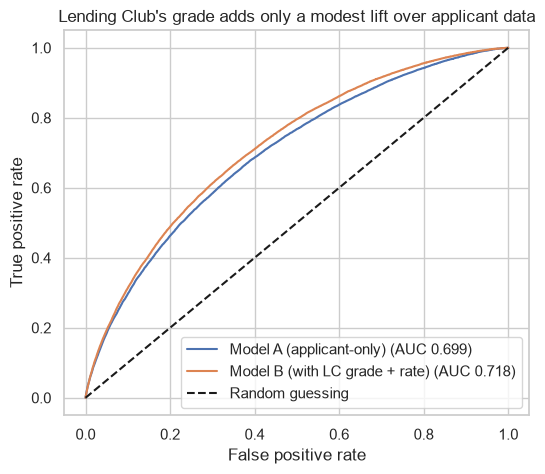

In [45]:
plt.figure(figsize=(6, 5))
for name, p in [("Model A (applicant-only)", p_A), ("Model B (with LC grade + rate)", p_B)]:
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guessing")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Lending Club's grade adds only a modest lift over applicant data")
plt.legend()
plt.savefig("../reports/figures/05_roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

In [46]:
def make_tree_preprocessor(num, cat):
    return ColumnTransformer([("num", "passthrough", num),
                              ("cat", OneHotEncoder(handle_unknown="ignore",
                                                    sparse_output=False), cat)])

gb = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1,
                                    early_stopping=True, random_state=42)
pipe_GB, p_GB = fit_and_score("Gradient boosting A (applicant-only)", gb, num_A, cat_A,
                              preprocessor=make_tree_preprocessor(num_A, cat_A))

Gradient boosting A (applicant-only): ROC AUC = 0.7085 | PR AUC = 0.3652


In [47]:
results = pd.DataFrame({
    "Model": ["Logistic A", "Logistic B", "Gradient boosting A"],
    "ROC AUC": [roc_auc_score(y_test, p) for p in (p_A, p_B, p_GB)],
    "PR AUC": [average_precision_score(y_test, p) for p in (p_A, p_B, p_GB)],
})
results.round(4)

,Model,ROC AUC,PR AUC
0,Logistic A,0.6994,0.3555
1,Logistic B,0.7181,0.3702
2,Gradient boosting A,0.7085,0.3652


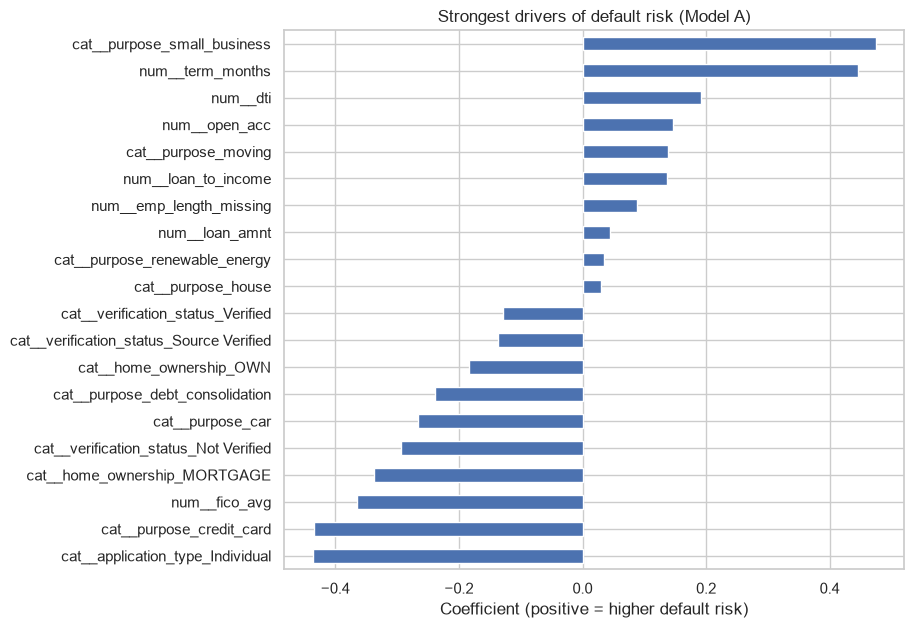

In [48]:
prep = pipe_A.named_steps["prep"]
names = prep.get_feature_names_out()
coefs = pd.Series(pipe_A.named_steps["model"].coef_[0], index=names).sort_values()
top = pd.concat([coefs.head(10), coefs.tail(10)])
top.plot(kind="barh", figsize=(8, 7))
plt.title("Strongest drivers of default risk (Model A)")
plt.xlabel("Coefficient (positive = higher default risk)")
plt.savefig("../reports/figures/06_coefficients.png", dpi=150, bbox_inches="tight")
plt.show()

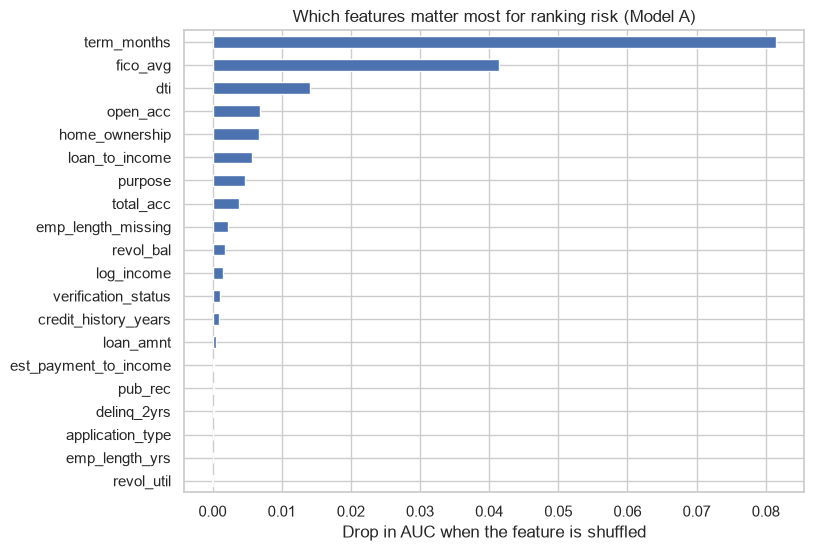

In [49]:
feats = num_A + cat_A
sample = test.sample(20000, random_state=1)
imp = permutation_importance(pipe_A, sample[feats], y_test.loc[sample.index],
                             scoring="roc_auc", n_repeats=3, random_state=1, n_jobs=-1)
pd.Series(imp.importances_mean, index=feats).sort_values().plot(kind="barh", figsize=(8, 6))
plt.title("Which features matter most for ranking risk (Model A)")
plt.xlabel("Drop in AUC when the feature is shuffled")
plt.savefig("../reports/figures/07_permutation_importance.png", dpi=150, bbox_inches="tight")
plt.show()

In [50]:
scored = pd.DataFrame({"p": p_A, "y": y_test.values})
scored["risk_decile"] = pd.qcut(scored["p"], 10, labels=range(1, 11))
decile = scored.groupby("risk_decile", observed=True).agg(
    avg_predicted=("p", "mean"), actual_default_rate=("y", "mean"))
decile.mul(100).round(1)

,avg_predicted,actual_default_rate
risk_decile,,
1,5.2,5.0
2,8.4,8.3
3,10.6,10.7
4,12.6,12.6
5,14.7,14.8
6,17.1,17.5
7,20.1,20.4
8,24.5,24.7
9,31.3,30.5


In [51]:
rows = []
for t in [0.10, 0.15, 0.20, 0.25, 0.30, 0.40]:
    approved = scored[scored["p"] < t]
    rows.append({
        "threshold": t,
        "approval_rate_%": len(approved) / len(scored) * 100,
        "default_rate_of_approved_%": approved["y"].mean() * 100,
        "defaults_avoided_%": (1 - approved["y"].sum() / scored["y"].sum()) * 100,
    })
pd.DataFrame(rows).round({"threshold": 2, "approval_rate_%": 1,
                          "default_rate_of_approved_%": 1, "defaults_avoided_%": 1})

,threshold,approval_rate_%,default_rate_of_approved_%,defaults_avoided_%
0,0.10,22.2,6.9,91.8
1,0.15,46.5,9.9,75.6
2,0.20,64.8,12.1,58.3
3,0.25,76.1,13.6,44.9
4,0.30,83.6,14.8,34.2
5,0.40,93.4,16.8,16.5


In [52]:
profit_if_paid = 0.15    # assumed net profit on a repaid loan, as a share of principal
loss_if_default = 0.60   # assumed net loss on a defaulted loan, after recoveries

rows = []
for t in [0.10, 0.15, 0.20, 0.25, 0.30, 0.40]:
    approved = scored[scored["p"] < t]
    profit = np.where(approved["y"] == 0, profit_if_paid, -loss_if_default).sum()
    rows.append({"threshold": t,
                 "approval_rate_%": len(approved) / len(scored) * 100,
                 "profit_per_100_applicants": profit / len(scored) * 100})
pd.DataFrame(rows).round(2)

,threshold,approval_rate_%,profit_per_100_applicants
0,0.10,22.23,2.18
1,0.15,46.48,3.53
2,0.20,64.75,3.83
3,0.25,76.08,3.63
4,0.30,83.63,3.25
5,0.40,93.43,2.23


In [53]:
thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.40]
scenarios = [(0.15, 0.60), (0.10, 0.60), (0.20, 0.60), (0.15, 0.40), (0.15, 0.80)]

out = {}
for gain, loss in scenarios:
    vals = []
    for t in thresholds:
        a = scored[scored["p"] < t]
        vals.append(np.where(a["y"] == 0, gain, -loss).sum() / len(scored) * 100)
    out[f"gain {gain:.0%} / loss {loss:.0%}"] = vals

sens = pd.DataFrame(out, index=thresholds).round(2)
display(sens)
print(sens.idxmax())

,gain 15% / loss 60%,gain 10% / loss 60%,gain 20% / loss 60%,gain 15% / loss 40%,gain 15% / loss 80%
0.10,2.18,1.15,3.22,2.49,1.88
0.15,3.53,1.43,5.62,4.45,2.61
0.20,3.83,0.98,6.67,5.40,2.26
0.25,3.63,0.35,6.92,5.71,1.56
0.30,3.25,-0.31,6.82,5.73,0.78
0.40,2.23,-1.66,6.12,5.37,-0.91


gain 15% / loss 60%    0.20
gain 10% / loss 60%    0.15
gain 20% / loss 60%    0.25
gain 15% / loss 40%    0.30
gain 15% / loss 80%    0.15
dtype: float64


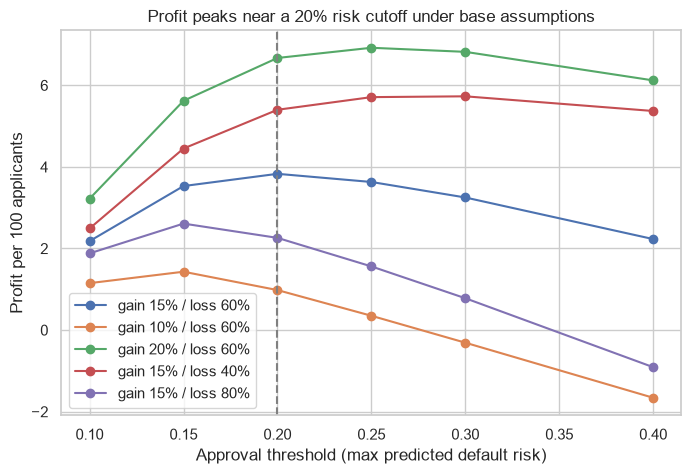

In [54]:
sens.plot(figsize=(8, 5), marker="o")
plt.axvline(0.20, color="gray", linestyle="--")
plt.xlabel("Approval threshold (max predicted default risk)")
plt.ylabel("Profit per 100 applicants")
plt.title("Profit peaks near a 20% risk cutoff under base assumptions")
plt.savefig("../reports/figures/08_profit_by_threshold.png", dpi=150, bbox_inches="tight")
plt.show()